# Практическая работа 4. Персонализированный roadmap для инженера

**Задачи:**
1. Построить граф компетенций на реальных данных рынка труда: вакансии и навыки.
2. Построить гетерогенный граф «человек – навык – проект». Узлы: навыки, инструменты и технологии, проекты (вакансии), роли, люди.
   Рёбра: «используется в», «требуется для», «развивает», «владеет». Веса: частота упоминаний + прогноз роста.
3. Обучить Heterogeneous GNN и визуализировать важность навыков.
4. Сформулировать персонализированные рекомендации по навыкам и пути обучения.

**Источники данных:**
- **Вакансии.** Основной источник по заданию — [API hh.ru](https://api.hh.ru/openapi/redoc) (функция `fetch_hh` ниже). реальные вакансии берутся из открытого API [Arbeitnow](https://www.arbeitnow.com/api/job-board-api)
  (IT-вакансии Германии и ЕС с полными текстами описаний).
- **Прогноз роста.** Окно вакансий слишком короткое (около недели), чтобы по нему мерить тренды. Поэтому рост навыка оцениваем по
  динамике доли вопросов с соответствующим тегом на Stack Overflow за 3 года ([StackExchange API](https://api.stackexchange.com/docs))
  и экстраполируем на следующий год.

In [1]:
# !pip install requests beautifulsoup4 networkx pyvis torch torch_geometric scikit-learn matplotlib pandas
import os, re, json, time, html, random, warnings
from collections import Counter, defaultdict
from datetime import datetime, timezone
from itertools import combinations

import numpy as np
import pandas as pd
import requests
import networkx as nx
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from IPython.display import HTML, display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric.transforms as T
from torch_geometric.data import HeteroData
from torch_geometric.nn import SAGEConv, Linear, to_hetero
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.manifold import TSNE

warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")
warnings.filterwarnings("ignore", category=UserWarning, module="torch_geometric")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cpu")        # граф небольшой; на CPU обучение быстрое и воспроизводимое (на CUDA scatter-операции недетерминированы)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.set_num_threads(1)            # параллельное суммирование float на нескольких потоках даёт разный порядок округлений
os.makedirs("data", exist_ok=True)
print("device:", device)

C:\Users\Ivan\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu


## 1. Сбор данных о вакансиях

In [ ]:
USE_HH = False                     
HH_USER_AGENT = "GraphRoadmapStudy/1.0 (your-email@example.com)"   # API hh.ru требует User-Agent вида "App/1.0 (email)"
HH_QUERIES = ["python разработчик", "java разработчик", "data scientist", "data engineer", "devops инженер",
              "frontend разработчик", "аналитик данных", "ml engineer", "golang", "QA инженер"]


def fetch_hh(queries, pages=3, area=113):
    """Вакансии hh.ru: поиск + детальная карточка с key_skills. area=113 - Россия."""
    s = requests.Session(); s.headers["HH-User-Agent"] = HH_USER_AGENT
    jobs, seen = [], set()
    for q in queries:
        for page in range(pages):
            r = s.get("https://api.hh.ru/vacancies", params={"text": q, "area": area, "per_page": 100, "page": page}, timeout=30)
            r.raise_for_status()
            for it in r.json()["items"]:
                if it["id"] in seen:
                    continue
                seen.add(it["id"])
                v = s.get(f"https://api.hh.ru/vacancies/{it['id']}", timeout=30).json()
                jobs.append({"source": "hh.ru", "title": v["name"], "url": v["alternate_url"],
                             "description": " ".join(k["name"] for k in v.get("key_skills", [])) + " " + v.get("description", ""),
                             "created_at": datetime.fromisoformat(v["published_at"]).timestamp(), "tags": []})
                time.sleep(0.2)
    return jobs


def fetch_arbeitnow(max_pages=40):
    jobs, page, retries = [], 1, 0
    while page <= max_pages:
        r = requests.get("https://www.arbeitnow.com/api/job-board-api", params={"page": page}, timeout=30)
        if r.status_code == 429 and retries < 3:          # превышен лимит запросов - ждём и повторяем
            retries += 1; time.sleep(30); continue
        if r.status_code != 200:
            print("остановились на странице", page, "код", r.status_code); break
        d = r.json(); jobs += d["data"]; retries = 0
        if not d["links"].get("next"):
            break
        page += 1; time.sleep(1.5)
    return jobs


CACHE = "data/hh_jobs.json" if USE_HH else "data/arbeitnow_jobs.json"
if os.path.exists(CACHE):
    raw_jobs = json.load(open(CACHE, encoding="utf-8"))
else:
    raw_jobs = fetch_hh(HH_QUERIES) if USE_HH else fetch_arbeitnow()
    json.dump(raw_jobs, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)

jobs = pd.DataFrame(raw_jobs)
jobs["text"] = jobs["description"].map(lambda s: html.unescape(BeautifulSoup(s, "html.parser").get_text(" ")))
jobs["date"] = pd.to_datetime(jobs["created_at"], unit="s")
print(f"Всего вакансий: {len(jobs)}, период: {jobs['date'].min():%d.%m.%Y} - {jobs['date'].max():%d.%m.%Y}")

Всего вакансий: 3863, период: 19.10.2026 - 26.10.2026


### 1.1 Словарь навыков и извлечение навыков из текстов

У hh.ru навыки приходят в поле `key_skills`. В других источниках их нужно извлекать из текста, поэтому используем словарь
из ~100 технологий с регулярными выражениями: учитываем синонимы (`k8s` → Kubernetes, `Postgres` → PostgreSQL),
регистр (Go, R, SAP) и контекст. Каждому навыку сопоставлен тег Stack Overflow для оценки тренда.

In [3]:
# навык: (категория, regex, флаги, тег Stack Overflow)
I, CS = re.I, 0
SKILLS = {
    # Языки
    "Python": ("язык", r"\bpython\b", I, "python"),
    "Java": ("язык", r"\bjava\b(?!\s?script)", I, "java"),
    "JavaScript": ("язык", r"javascript|\bJS\b", CS, "javascript"),
    "TypeScript": ("язык", r"typescript", I, "typescript"),
    "Go": ("язык", r"\bGolang\b|\bGo\b(?=\s*(,|/|\)|and\b|or\b|und\b|oder\b|developer|engineer|programming))", CS, "go"),
    "C++": ("язык", r"C\+\+", CS, "c++"),
    "C#": ("язык", r"C#", CS, "c#"),
    "Rust": ("язык", r"\bRust\b", CS, "rust"),
    "Kotlin": ("язык", r"\bkotlin\b", I, "kotlin"),
    "Swift": ("язык", r"\bSwift\b", CS, "swift"),
    "Scala": ("язык", r"\bScala\b", CS, "scala"),
    "PHP": ("язык", r"\bPHP\b", I, "php"),
    "Ruby": ("язык", r"\bRuby\b", CS, "ruby"),
    "R": ("язык", r"\bPython\s*(,|/|or|and|oder|und)\s*R\b|\bR\s*(,|/|or|and|oder|und)\s*Python\b|\bRStudio\b|\bR programming", CS, "r"),
    "SQL": ("язык", r"\bSQL\b", I, "sql"),
    "Bash": ("язык", r"\bbash\b|shell[- ]script", I, "bash"),
    "Dart": ("язык", r"\bDart\b", CS, "dart"),
    "ABAP": ("язык", r"\bABAP\b", CS, "abap"),
    # Frontend
    "React": ("frontend", r"\breact(\.?js)?\b(?!\s?native)", I, "reactjs"),
    "Angular": ("frontend", r"\bangular(js)?\b", I, "angular"),
    "Vue.js": ("frontend", r"\bvue(\.?js)?\b", I, "vue.js"),
    "Next.js": ("frontend", r"\bnext\.?js\b", I, "next.js"),
    "HTML/CSS": ("frontend", r"\bHTML5?\b|\bCSS3?\b", I, "css"),
    "Redux": ("frontend", r"\bredux\b", I, "redux"),
    "Tailwind": ("frontend", r"\btailwind", I, "tailwind-css"),
    # Backend
    "Node.js": ("backend", r"\bnode\.?js\b|\bnodejs\b", I, "node.js"),
    "Django": ("backend", r"\bdjango\b", I, "django"),
    "Flask": ("backend", r"\bflask\b", I, "flask"),
    "FastAPI": ("backend", r"\bfastapi\b", I, "fastapi"),
    "Spring": ("backend", r"\bSpring(\s?Boot|\s?Framework)?\b", CS, "spring-boot"),
    ".NET": ("backend", r"(?<![\w/.])\.NET\b|\bASP\.NET", CS, ".net"),
    "Ruby on Rails": ("backend", r"ruby on rails|\bRails\b", I, "ruby-on-rails"),
    "Laravel": ("backend", r"\blaravel\b", I, "laravel"),
    "Symfony": ("backend", r"\bsymfony\b", I, "symfony"),
    "GraphQL": ("backend", r"\bgraphql\b", I, "graphql"),
    "REST API": ("backend", r"\bREST(ful)?\b", CS, "rest"),
    "gRPC": ("backend", r"\bgrpc\b", I, "grpc"),
    "Microservices": ("backend", r"micro-?services?", I, "microservices"),
    "System Design": ("backend", r"system design|software architecture|softwarearchitektur|distributed systems", I, "system-design"),
    # Базы данных
    "PostgreSQL": ("БД", r"\bpostgre(sql|s)\b", I, "postgresql"),
    "MySQL": ("БД", r"\bmysql\b|\bmariadb\b", I, "mysql"),
    "MongoDB": ("БД", r"\bmongo(db)?\b", I, "mongodb"),
    "Redis": ("БД", r"\bredis\b", I, "redis"),
    "Elasticsearch": ("БД", r"\belastic(search)?\b|\bopensearch\b", I, "elasticsearch"),
    "Oracle": ("БД", r"\boracle\b", I, "oracle-database"),
    "NoSQL": ("БД", r"\bnosql\b", I, "nosql"),
    "Cassandra": ("БД", r"\bcassandra\b", I, "cassandra"),
    "DynamoDB": ("БД", r"\bdynamodb\b", I, "amazon-dynamodb"),
    "ClickHouse": ("БД", r"\bclickhouse\b", I, "clickhouse"),
    # Data / ML
    "pandas": ("data/ML", r"\bpandas\b", I, "pandas"),
    "NumPy": ("data/ML", r"\bnumpy\b", I, "numpy"),
    "scikit-learn": ("data/ML", r"scikit|sklearn", I, "scikit-learn"),
    "PyTorch": ("data/ML", r"\bpytorch\b", I, "pytorch"),
    "TensorFlow": ("data/ML", r"\btensorflow\b", I, "tensorflow"),
    "Keras": ("data/ML", r"\bkeras\b", I, "keras"),
    "Hugging Face": ("data/ML", r"hugging\s?face|\btransformers library", I, "huggingface-transformers"),
    "LangChain": ("data/ML", r"\blangchain\b", I, "langchain"),
    "Machine Learning": ("data/ML", r"machine learning|maschinelles lernen|\bML\b", CS, "machine-learning"),
    "Deep Learning": ("data/ML", r"deep learning|neural network", I, "deep-learning"),
    "NLP": ("data/ML", r"\bNLP\b|natural language processing", CS, "nlp"),
    "Computer Vision": ("data/ML", r"computer vision|bildverarbeitung", I, "computer-vision"),
    "LLM": ("data/ML", r"\bLLMs?\b|large language model", CS, "large-language-model"),
    "Generative AI": ("data/ML", r"\bgen(erative)?\s?AI\b|generative ki", I, "generative-ai"),
    "RAG": ("data/ML", r"\bRAG\b|retrieval[- ]augmented", CS, "retrieval-augmented-generation"),
    "MLOps": ("data/ML", r"\bmlops\b", I, "mlops"),
    "Statistics": ("data/ML", r"statistic|statistik", I, "statistics"),
    "A/B Testing": ("data/ML", r"a/b[- ]test", I, "ab-testing"),
    "Spark": ("data/ML", r"\bspark\b|pyspark", I, "apache-spark"),
    "Kafka": ("data/ML", r"\bkafka\b", I, "apache-kafka"),
    "Airflow": ("data/ML", r"\bairflow\b", I, "airflow"),
    "dbt": ("data/ML", r"\bdbt\b", I, "dbt"),
    "Databricks": ("data/ML", r"\bdatabricks\b", I, "databricks"),
    "Snowflake": ("data/ML", r"\bsnowflake\b", I, "snowflake-cloud-data-platform"),
    "BigQuery": ("data/ML", r"\bbigquery\b", I, "google-bigquery"),
    "ETL": ("data/ML", r"\bETL\b|\bELT\b", CS, "etl"),
    "Data Warehouse": ("data/ML", r"data\s?warehous|\bDWH\b", I, "data-warehouse"),
    "Tableau": ("data/ML", r"\btableau\b", I, "tableau-api"),
    "Power BI": ("data/ML", r"power\s?bi", I, "powerbi"),
    "Excel": ("data/ML", r"\bexcel\b", I, "excel"),
    # Cloud / DevOps
    "AWS": ("cloud/DevOps", r"\bAWS\b|amazon web services", CS, "amazon-web-services"),
    "Azure": ("cloud/DevOps", r"\bazure\b", I, "azure"),
    "GCP": ("cloud/DevOps", r"\bGCP\b|google cloud", CS, "google-cloud-platform"),
    "Docker": ("cloud/DevOps", r"\bdocker\b", I, "docker"),
    "Kubernetes": ("cloud/DevOps", r"kubernetes|\bk8s\b", I, "kubernetes"),
    "Terraform": ("cloud/DevOps", r"\bterraform\b", I, "terraform"),
    "Ansible": ("cloud/DevOps", r"\bansible\b", I, "ansible"),
    "Helm": ("cloud/DevOps", r"\bHelm\b", CS, "kubernetes-helm"),
    "Jenkins": ("cloud/DevOps", r"\bjenkins\b", I, "jenkins"),
    "GitLab CI": ("cloud/DevOps", r"\bgitlab\b", I, "gitlab-ci"),
    "GitHub Actions": ("cloud/DevOps", r"github actions", I, "github-actions"),
    "CI/CD": ("cloud/DevOps", r"\bCI\s?/\s?CD\b|continuous (integration|delivery|deployment)", I, "continuous-integration"),
    "Linux": ("cloud/DevOps", r"\blinux\b", I, "linux"),
    "Prometheus": ("cloud/DevOps", r"\bprometheus\b", I, "prometheus"),
    "Grafana": ("cloud/DevOps", r"\bgrafana\b", I, "grafana"),
    "Git": ("cloud/DevOps", r"\bgit\b", I, "git"),
    # Mobile
    "Android": ("mobile", r"\bandroid\b", I, "android"),
    "iOS": ("mobile", r"\biOS\b", CS, "ios"),
    "Flutter": ("mobile", r"\bflutter\b", I, "flutter"),
    "React Native": ("mobile", r"react\s?native", I, "react-native"),
    # Тестирование
    "Selenium": ("testing", r"\bselenium\b", I, "selenium-webdriver"),
    "Cypress": ("testing", r"\bcypress\b", I, "cypress"),
    "Playwright": ("testing", r"\bplaywright\b", I, "playwright"),
    "pytest": ("testing", r"\bpytest\b", I, "pytest"),
    "Jest": ("testing", r"\bJest\b", CS, "jestjs"),
    "TDD": ("testing", r"\bTDD\b|test[- ]driven", I, "tdd"),
    # Практики и инструменты
    "Agile": ("практики", r"\bagile?\b", I, "agile"),
    "Scrum": ("практики", r"\bscrum\b", I, "scrum"),
    "Jira": ("практики", r"\bjira\b", I, "jira"),
    "SAP": ("практики", r"\bSAP\b", CS, "sap"),
    "Embedded": ("практики", r"embedded[- ](software|systems?|c\b|linux|development|entwickl)|firmware|eingebettete", I, "embedded"),
}
SKILL_RE = {s: re.compile(p, f) for s, (_, p, f, _) in SKILLS.items()}
CATEGORY = {s: v[0] for s, v in SKILLS.items()}
print("Навыков в словаре:", len(SKILLS))


def extract_skills(text):
    return sorted(s for s, rx in SKILL_RE.items() if rx.search(text))

Навыков в словаре: 110


### 1.2 Отбор IT-вакансий и определение роли

Роль («тип проекта») определяем по названию вакансии. Порядок правил важен: сначала более специфичные роли.

In [4]:
IT_TITLE = re.compile(r"engineer|developer|entwickler|devops|\bdata\b|software|programm|backend|back-end|frontend|front-end|"
                      r"full.?stack|machine learning|\bml\b|\bai\b|\bsre\b|cloud|architect|разработчик|программист|инженер|аналитик|"
                      r"scientist|analyst|\bqa\b|tester|mobile|android|\bios\b", re.I)
ROLE_RULES = [
    ("Security", r"security|secops|pentest|безопасн"),
    ("Data Scientist", r"data scien"),
    ("ML/AI Engineer", r"\bml\b|machine learning|\bai\b|\bki\b|deep learning|\bllm|\bnlp\b|computer vision|ml-"),
    ("Data Engineer", r"data engineer|data platform|\betl\b|analytics engineer|dateningenieur"),
    ("Data/BI Analyst", r"analyst|analytiker|аналитик|\bbi\b|business intelligence"),
    ("DevOps/Cloud", r"devops|\bsre\b|site reliability|platform engineer|cloud|infrastructure|infrastruktur|kubernetes"),
    ("Mobile", r"android|\bios\b|mobile|flutter"),
    ("QA/Test", r"\bqa\b|test|quality assurance|тестиров"),
    ("Embedded", r"embedded|firmware|hardware|fpga"),
    ("Fullstack", r"full.?stack"),
    ("Frontend", r"frontend|front-end|\breact\b|angular|\bvue\b|\bui\b"),
    ("Backend", r"backend|back-end|\bjava\b|python|golang|\.net|\bphp\b|node|\bc#|c\+\+"),
    ("Software Engineer", r"."),
]
ROLE_RULES = [(r, re.compile(p, re.I)) for r, p in ROLE_RULES]

def detect_role(title):
    return next(r for r, rx in ROLE_RULES if rx.search(title))

it = jobs[jobs["title"].str.contains(IT_TITLE)].copy()
it["skills"] = (it["title"] + " " + it["text"]).map(extract_skills)
it = it[it["skills"].map(len) >= 2].drop_duplicates(subset=["title", "company_name"] if "company_name" in it else ["title"])
it["role"] = it["title"].map(detect_role)
it = it.reset_index(drop=True)
print(f"IT-вакансий с >= 2 навыками: {len(it)}; навыков на вакансию: медиана {it['skills'].map(len).median():.0f}")
print(it["role"].value_counts().to_string())
it[["title", "role", "skills"]].head(8)

IT-вакансий с >= 2 навыками: 931; навыков на вакансию: медиана 6
role
Software Engineer    296
ML/AI Engineer       163
Backend               92
DevOps/Cloud          72
Data Engineer         61
Data/BI Analyst       56
Fullstack             44
Data Scientist        37
Security              28
Frontend              25
Mobile                21
QA/Test               18
Embedded              18


,title,role,skills
0,DevOps Engineer (m/w/d),DevOps/Cloud,"[.NET, AWS, Azure, CI/CD, Docker, GCP, Helm, K..."
1,ETL-Entwickler:in im Bankenumfeld (m/w/d),Data Engineer,"[Data Warehouse, ETL, Java, MySQL, Oracle, Pos..."
2,Embedded Softwareentwickler (m/w/d),Embedded,"[C++, Embedded, Git, Jenkins, Jira, Linux]"
3,Automation & Safety Software Engineer (f/m/d),Software Engineer,"[C++, Python, Ruby on Rails]"
4,Test Engineer - Automated Systems (f/m/d),QA/Test,"[C#, C++, Embedded, Python]"
5,Backend Softwareentwickler (m/w/d),Backend,"[Agile, MySQL, PHP]"
6,Solution Support (w/m/d) Release Engineer,Software Engineer,"[CI/CD, Linux]"
7,"Fullstack Software Developer (m/w/d) – Java, A...",Fullstack,"[Angular, GitHub Actions, Java, Kafka, Postgre..."


### 1.3 Прогноз роста навыков (Stack Overflow trends)

Для каждого навыка берём долю вопросов с его тегом среди всех вопросов Stack Overflow за 3 последовательных года.
Затем строим линейный тренд по логарифму доли и экстраполируем на следующий год. Теги, у которых меньше 20 вопросов в год,
пропускаем (такой тренд — шум), а прогноз ограничиваем диапазоном [-90%, +150%]:
$\text{growth} = \hat{s}_{t+1} / s_t - 1$. Число запросов ограничено квотой API (300 в сутки без ключа), поэтому ответы кэшируются.

In [5]:
SO_CACHE = "data/so_trends.json"
so_cache = json.load(open(SO_CACHE)) if os.path.exists(SO_CACHE) else {}
anchor = datetime(2026, 10, 1, tzinfo=timezone.utc)          # фиксированная точка - чтобы кэш был воспроизводим
YEAR = 365 * 24 * 3600
periods = [(int(anchor.timestamp()) - (k + 1) * YEAR, int(anchor.timestamp()) - k * YEAR) for k in (2, 1, 0)]
quota_ok = True

def so_total(tag, frm, to):
    global quota_ok
    key = f"{tag}|{frm}|{to}"
    if key in so_cache:
        return so_cache[key]
    if not quota_ok:
        return None
    params = {"site": "stackoverflow", "fromdate": frm, "todate": to, "filter": "total"}
    if tag:
        params["tagged"] = tag
    r = requests.get("https://api.stackexchange.com/2.3/questions", params=params, timeout=30)
    d = r.json()
    if "total" not in d:
        print("StackExchange API:", d.get("error_message", d)); quota_ok = False; return None
    so_cache[key] = d["total"]
    json.dump(so_cache, open(SO_CACHE, "w"))
    time.sleep(0.1)
    return d["total"]

used_skills = sorted({s for ss in it["skills"] for s in ss})
totals = [so_total(None, a, b) for a, b in periods]
trend = {}
for s in used_skills:
    counts = [so_total(SKILLS[s][3], a, b) for a, b in periods]
    if None in counts or None in totals or min(counts) < 20:       # слишком мало вопросов - тренд ненадёжен
        trend[s] = np.nan; continue
    share = np.array(counts) / np.array(totals)
    slope, intercept = np.polyfit(np.arange(3), np.log(share), 1)
    trend[s] = float(np.clip(np.exp(intercept + slope * 3) / share[-1] - 1, -0.9, 1.5))
print("Вопросов на SO по годам:", totals)
print("Навыков с оценкой тренда:", sum(~np.isnan(list(trend.values()))), "из", len(used_skills))

StackExchange API: too many requests from this IP, more requests available in 85223 seconds
Вопросов на SO по годам: [480294, 156131, 33626]
Навыков с оценкой тренда: 77 из 110


## 2. Граф компетенций и гетерогенный граф «человек – навык – проект»

### 2.1 Веса навыков
- **Частота** $f_s$ — доля вакансий, где упоминается навык.
- **Рост** $g_s$ — прогноз изменения доли навыка на следующий год (по Stack Overflow); где тренда нет, ставим медиану.
- **Итоговый вес** $w_s = 0.7 \cdot \tilde f_s + 0.3 \cdot \tilde g_s$, где $\tilde{\cdot}$ — min-max нормировка (рост ограничен 5–95 перцентилями).

In [6]:
N = len(it)
freq = Counter(s for ss in it["skills"] for s in ss)
skills_df = pd.DataFrame({"skill": used_skills})
skills_df["category"] = skills_df["skill"].map(CATEGORY)
skills_df["count"] = skills_df["skill"].map(freq)
skills_df["freq"] = skills_df["count"] / N
skills_df["growth"] = skills_df["skill"].map(trend)
skills_df["growth"] = skills_df["growth"].fillna(skills_df["growth"].median())
mm = lambda x: (x - x.min()) / (x.max() - x.min() + 1e-12)
g_clip = skills_df["growth"].clip(*skills_df["growth"].quantile([0.05, 0.95]))
skills_df["freq_n"], skills_df["growth_n"] = mm(skills_df["freq"]), mm(g_clip)
skills_df["weight"] = 0.7 * skills_df["freq_n"] + 0.3 * skills_df["growth_n"]
skills_df = skills_df.sort_values("weight", ascending=False).reset_index(drop=True)
has_trend = skills_df["skill"].map(lambda s: not np.isnan(trend[s]))
print("Самый быстрый прогнозируемый рост:", ", ".join(f"{r.skill} ({r.growth:+.0%})" for r in skills_df[has_trend].nlargest(8, "growth").itertuples()))
print("Самое сильное падение:", ", ".join(f"{r.skill} ({r.growth:+.0%})" for r in skills_df[has_trend].nsmallest(8, "growth").itertuples()))
skills_df.head(20).round(3)

Самый быстрый прогнозируемый рост: Embedded (+46%), C++ (+35%), Rust (+27%), Swift (+20%), Playwright (+18%), Git (+15%), LLM (+13%), Redis (+12%)
Самое сильное падение: React (-41%), MySQL (-36%), Jest (-33%), Elasticsearch (-33%), Flask (-32%), Kubernetes (-28%), Django (-28%), AWS (-28%)


,skill,category,count,freq,growth,freq_n,growth_n,weight
0,Python,язык,478,0.513,-0.059,1.000,0.525,0.858
1,LLM,data/ML,210,0.226,0.132,0.438,0.980,0.601
2,Machine Learning,data/ML,237,0.255,-0.040,0.495,0.569,0.517
3,Git,cloud/DevOps,141,0.151,0.148,0.294,1.000,0.505
4,SQL,язык,259,0.278,-0.149,0.541,0.309,0.471
5,Java,язык,132,0.142,0.086,0.275,0.869,0.453
6,CI/CD,cloud/DevOps,242,0.260,-0.145,0.505,0.319,0.449
7,REST API,backend,102,0.110,0.117,0.212,0.944,0.432
8,C++,язык,83,0.089,0.353,0.172,1.000,0.420
9,Linux,cloud/DevOps,106,0.114,0.076,0.220,0.846,0.408


In [7]:
# Граф совместной встречаемости навыков (граф компетенций)
pair_cnt = Counter(p for ss in it["skills"] for p in combinations(sorted(ss), 2))
SG = nx.Graph()
for _, r in skills_df.iterrows():
    SG.add_node(r["skill"], category=r["category"], weight=r["weight"], freq=r["freq"], growth=r["growth"])
for (a, b), c in pair_cnt.items():
    if c >= 3:
        # PMI показывает, насколько пара встречается чаще случайного
        pmi = np.log(c * N / (freq[a] * freq[b]))
        SG.add_edge(a, b, count=c, pmi=pmi)
SG.remove_nodes_from([n for n in list(SG) if SG.degree(n) == 0])
skill_pr = nx.pagerank(SG, weight="count")
print(SG)
print("Топ-10 навыков по PageRank в графе совместной встречаемости:")
print(pd.Series(skill_pr).sort_values(ascending=False).head(10).round(4).to_string())

Graph with 108 nodes and 2153 edges
Топ-10 навыков по PageRank в графе совместной встречаемости:
Python              0.0574
AWS                 0.0412
CI/CD               0.0381
SQL                 0.0334
Kubernetes          0.0325
Machine Learning    0.0283
Azure               0.0270
Docker              0.0264
TypeScript          0.0260
LLM                 0.0245


### 2.2 Люди

Реальных резюме у нас нет (API резюме hh.ru платный и требует согласия соискателей). Поэтому **моделируем популяцию инженеров
на основе реальных вакансий**: человек «работал» на позиции, похожей на случайную вакансию, и владеет каждым её навыком
с вероятностью 0.7 плюс 1–2 случайными популярными навыками. Целевая роль у 70% людей совпадает с текущей, у 30% это
другая роль (смена специализации). Отдельно добавляем три **персоны**, для которых строим roadmap.
Свой профиль можно задать, добавив его в словарь `PERSONAS`.

In [8]:
PERSONAS = {
    "Студент финтеха -> Data Scientist": (["Python", "SQL", "pandas", "NumPy", "Statistics", "Excel", "Git"], "Data Scientist"),
    "Java backend -> DevOps/Cloud": (["Java", "Spring", "SQL", "PostgreSQL", "REST API", "Git", "Linux", "Docker"], "DevOps/Cloud"),
    "Frontend -> ML/AI Engineer": (["JavaScript", "TypeScript", "React", "HTML/CSS", "Git", "Python"], "ML/AI Engineer"),
}
for p, (sk, role) in PERSONAS.items():
    missing = [s for s in sk if s not in used_skills]
    assert not missing, f"{p}: навыков нет в данных {missing}"

roles = sorted(it["role"].unique())
rng = np.random.default_rng(SEED)
popular = skills_df["skill"].head(30).tolist()
people = []
for k in range(600):
    job = it.iloc[rng.integers(N)]
    sk = {s for s in job["skills"] if rng.random() < 0.7} | set(rng.choice(popular, size=rng.integers(1, 3), replace=False))
    target = job["role"] if rng.random() < 0.7 else roles[rng.integers(len(roles))]
    if len(sk) >= 2:
        people.append({"name": f"person_{k}", "skills": sorted(sk), "target": target})
for p, (sk, role) in PERSONAS.items():
    people.append({"name": p, "skills": sk, "target": role})
people = pd.DataFrame(people)
print("Людей в графе:", len(people), "(из них персон:", len(PERSONAS), ")")

Людей в графе: 599 (из них персон: 3 )


### 2.3 Гетерогенный граф

| Тип узла | Количество | Признаки |
|---|---|---|
| `skill` (навык / инструмент / технология) | ~100 | категория (one-hot), log-частота, рост + обучаемый эмбеддинг |
| `project` (вакансия = проект/позиция) | ~1000 | роль (one-hot) |
| `role` | 13 | обучаемый эмбеддинг |
| `person` | ~600 | константа (представление строится только из соседей, индуктивно) |

| Ребро | Смысл | Вес |
|---|---|---|
| `project –requires→ skill` (обратное: `skill –used_in→ project`) | навык используется в проекте | вес навыка $w_s$ |
| `project –of→ role` | проект относится к роли | 1 |
| `skill –required_for→ role` | навык требуется для роли | доля вакансий роли с навыком × (1 + рост) |
| `person –has→ skill` | человек владеет навыком | 1 |
| `person –targets→ role` | целевая роль человека | 1 |
| `skill –cooccurs– skill` | навыки встречаются вместе (развивают друг друга) | PMI |

In [9]:
skill_list = skills_df["skill"].tolist()
sidx = {s: k for k, s in enumerate(skill_list)}
ridx = {r: k for k, r in enumerate(roles)}
cats = sorted(skills_df["category"].unique())

role_share = pd.DataFrame(0.0, index=roles, columns=skill_list)
for r, grp in it.groupby("role"):
    c = Counter(s for ss in grp["skills"] for s in ss)
    for s, v in c.items():
        role_share.loc[r, s] = v / len(grp)

def ei(pairs):
    return torch.tensor(np.array(pairs).T, dtype=torch.long) if len(pairs) else torch.empty(2, 0, dtype=torch.long)

data = HeteroData()
x_skill = np.zeros((len(skill_list), len(cats) + 2), dtype=np.float32)
for k, r in skills_df.iterrows():
    x_skill[k, cats.index(r["category"])] = 1
    x_skill[k, -2] = np.log1p(r["count"]) / np.log1p(skills_df["count"].max())
    x_skill[k, -1] = np.clip(r["growth"], -1, 1)
data["skill"].x = torch.tensor(x_skill)
data["project"].x = F.one_hot(torch.tensor([ridx[r] for r in it["role"]]), len(roles)).float()
data["role"].x = torch.eye(len(roles))
data["person"].x = torch.ones(len(people), 1)

w_skill = dict(zip(skills_df["skill"], skills_df["weight"]))
req = [(j, sidx[s]) for j, ss in enumerate(it["skills"]) for s in ss]
data["project", "requires", "skill"].edge_index = ei(req)
data["project", "requires", "skill"].edge_weight = torch.tensor([w_skill[skill_list[s]] for _, s in req])
data["project", "of", "role"].edge_index = ei([(j, ridx[r]) for j, r in enumerate(it["role"])])
srf = [(sidx[s], ridx[r]) for r in roles for s in skill_list if role_share.loc[r, s] >= 0.05]
data["skill", "required_for", "role"].edge_index = ei(srf)
data["skill", "required_for", "role"].edge_weight = torch.tensor(
    [role_share.loc[roles[r], skill_list[s]] * (1 + np.clip(w_growth, -0.5, 1)) for s, r in srf
     for w_growth in [skills_df.loc[s, "growth"]]], dtype=torch.float)
co = [(sidx[a], sidx[b]) for a, b in SG.edges() if SG[a][b]["pmi"] > 0]
data["skill", "cooccurs", "skill"].edge_index = ei(co + [(b, a) for a, b in co])
data["person", "has", "skill"].edge_index = ei([(i, sidx[s]) for i, ss in enumerate(people["skills"]) for s in ss])
data["person", "targets", "role"].edge_index = ei([(i, ridx[r]) for i, r in enumerate(people["target"])])

data = T.ToUndirected()(data)       # добавляет обратные рёбра: skill -used_in-> project (rev_requires) и т.д.
data

HeteroData(
  skill={ x=[110, 11] },
  project={ x=[931, 13] },
  role={ x=[13, 13] },
  person={ x=[599, 1] },
  (project, requires, skill)={
    edge_index=[2, 6544],
    edge_weight=[6544],
  },
  (project, of, role)={ edge_index=[2, 931] },
  (skill, required_for, role)={
    edge_index=[2, 428],
    edge_weight=[428],
  },
  (skill, cooccurs, skill)={ edge_index=[2, 3384] },
  (person, has, skill)={ edge_index=[2, 3791] },
  (person, targets, role)={ edge_index=[2, 599] },
  (skill, rev_requires, project)={
    edge_index=[2, 6544],
    edge_weight=[6544],
  },
  (role, rev_of, project)={ edge_index=[2, 931] },
  (role, rev_required_for, skill)={
    edge_index=[2, 428],
    edge_weight=[428],
  },
  (skill, rev_has, person)={ edge_index=[2, 3791] },
  (role, rev_targets, person)={ edge_index=[2, 599] }
)

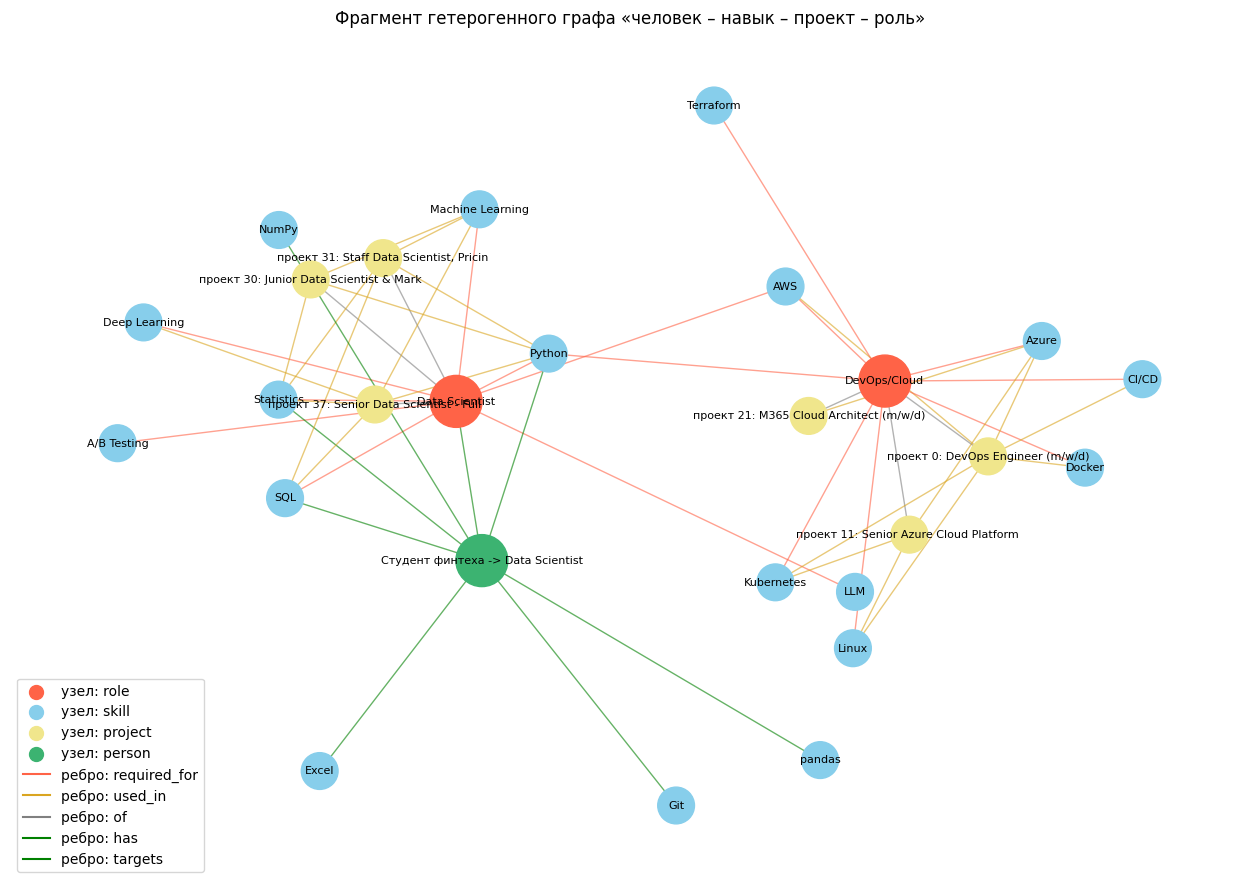

In [10]:
# Визуализация фрагмента гетерогенного графа: 2 роли, их топ-навыки, несколько проектов и одна персона
persona = list(PERSONAS)[0]
H = nx.Graph()
show_roles = ["Data Scientist", "DevOps/Cloud"]
for r in show_roles:
    H.add_node(r, t="role")
    for s in role_share.loc[r].sort_values(ascending=False).head(8).index:
        H.add_node(s, t="skill"); H.add_edge(s, r, rel="required_for")
    for j in it.index[it["role"] == r][:3]:
        pj = f"проект {j}: {it.loc[j, 'title'][:28]}"
        H.add_node(pj, t="project"); H.add_edge(pj, r, rel="of")
        for s in it.loc[j, "skills"]:
            if s in H:
                H.add_edge(s, pj, rel="used_in")
H.add_node(persona, t="person")
for s in PERSONAS[persona][0]:
    if s not in H:
        H.add_node(s, t="skill")
    H.add_edge(persona, s, rel="has")
H.add_edge(persona, PERSONAS[persona][1], rel="targets")

col = {"role": "tomato", "skill": "skyblue", "project": "khaki", "person": "mediumseagreen"}
ecol = {"required_for": "tomato", "used_in": "goldenrod", "of": "gray", "has": "green", "targets": "green"}
plt.figure(figsize=(16, 11))
hp = nx.spring_layout(H, seed=3, k=0.9)
nx.draw_networkx_edges(H, hp, edge_color=[ecol[d["rel"]] for _, _, d in H.edges(data=True)], alpha=0.6)
nx.draw_networkx_nodes(H, hp, node_color=[col[H.nodes[n]["t"]] for n in H], node_size=[1400 if H.nodes[n]["t"] in ("role", "person") else 700 for n in H])
nx.draw_networkx_labels(H, hp, font_size=8)
for t, c in col.items():
    plt.scatter([], [], color=c, s=100, label=f"узел: {t}")
for rname, c in ecol.items():
    plt.plot([], [], color=c, label=f"ребро: {rname}")
plt.legend(loc="lower left"); plt.axis("off")
plt.title("Фрагмент гетерогенного графа «человек – навык – проект – роль»")
plt.show()

## 3. Heterogeneous GNN

**Задача обучения:** предсказание связей двух типов: `person –has→ skill` (чем владеет человек) и `project –requires→ skill`
(что нужно проекту). Модель — двухслойный GraphSAGE, преобразованный в гетерогенный через `to_hetero`: для каждого типа
ребра свои веса, сообщения от разных типов суммируются. Декодер — скалярное произведение эмбеддингов плюс обучаемое смещение навыка
(его «базовая популярность»): $\hat y = \sigma(z_u^\top z_s + b_s)$.
Разбиение рёбер 80/10/10. 30% обучающих рёбер используются только как цели лосса и не участвуют в передаче сообщений
(`disjoint_train_ratio`), иначе модель «видит» целевое ребро через сообщения и переобучается. Негативы сэмплируются заново на каждой эпохе.

Бейзлайн для сравнения — **популярность**: score пары равен частоте навыка на рынке.

эпох: 352, лучший средний val ROC-AUC: 0.8181


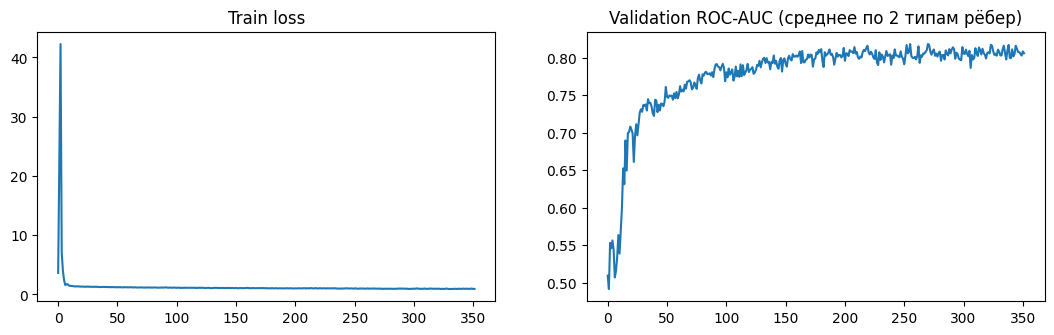

In [11]:
TARGETS = [("person", "has", "skill"), ("project", "requires", "skill")]
REVS = [("skill", "rev_has", "person"), ("skill", "rev_requires", "project")]
torch.manual_seed(SEED)
split = T.RandomLinkSplit(num_val=0.1, num_test=0.1, is_undirected=True, edge_types=TARGETS, rev_edge_types=REVS,
                          add_negative_train_samples=False, neg_sampling_ratio=1.0,
                          disjoint_train_ratio=0.3)   # 30% train-рёбер только для лосса, без передачи сообщений
train_data, val_data, test_data = [d.to(device) for d in split(data)]


class SAGE(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.c1 = SAGEConv((-1, -1), hidden)
        self.c2 = SAGEConv((-1, -1), hidden)

    def forward(self, x, edge_index):
        x = F.dropout(self.c1(x, edge_index).relu(), p=0.2, training=self.training)
        return self.c2(x, edge_index)


class HeteroLinkModel(nn.Module):
    def __init__(self, metadata, hidden=128):
        super().__init__()
        self.skill_emb = nn.Embedding(len(skill_list), 32)
        self.role_emb = nn.Embedding(len(roles), 16)
        self.lin = nn.ModuleDict({t: Linear(-1, hidden) for t in metadata[0]})
        self.gnn = to_hetero(SAGE(hidden), metadata, aggr="sum")
        self.skill_bias = nn.Embedding(len(skill_list), 1)     # обучаемая "базовая популярность" навыка
        nn.init.zeros_(self.skill_bias.weight)

    def forward(self, d):
        x = dict(d.x_dict)
        x["skill"] = torch.cat([x["skill"], self.skill_emb.weight], 1)
        x["role"] = torch.cat([x["role"], self.role_emb.weight], 1)
        x = {t: self.lin[t](v) for t, v in x.items()}
        return self.gnn(x, d.edge_index_dict)

    def score(self, z, et, pairs):
        return (z[et[0]][pairs[0]] * z[et[2]][pairs[1]]).sum(-1) + self.skill_bias.weight[pairs[1], 0]

    def all_scores(self, z, src_type):
        """Логиты для всех пар (узел src_type, навык)."""
        return (z[src_type] @ z["skill"].t() + self.skill_bias.weight[:, 0]).detach()


model = HeteroLinkModel(data.metadata()).to(device)
with torch.no_grad():
    model(train_data)                                   # инициализация ленивых слоёв
opt = torch.optim.Adam(model.parameters(), lr=0.003, weight_decay=1e-5)


def evaluate(d):
    model.eval()
    with torch.no_grad():
        z = model(d)
        out = {}
        for et in TARGETS:
            y = d[et].edge_label.cpu().numpy()
            p = torch.sigmoid(model.score(z, et, d[et].edge_label_index)).cpu().numpy()
            out[et[1]] = (y, p)
    return out


history, best, best_state, wait = [], 0, None, 0
for epoch in range(600):
    model.train(); opt.zero_grad()
    z = model(train_data)
    loss = 0
    for et in TARGETS:
        pos = train_data[et].edge_label_index
        neg = torch.stack([torch.randint(0, train_data[et[0]].num_nodes, (pos.size(1),), device=device),
                           torch.randint(0, train_data["skill"].num_nodes, (pos.size(1),), device=device)])
        logits = torch.cat([model.score(z, et, pos), model.score(z, et, neg)])
        labels = torch.cat([torch.ones(pos.size(1)), torch.zeros(pos.size(1))]).to(device)
        loss = loss + F.binary_cross_entropy_with_logits(logits, labels)
    loss.backward(); opt.step()
    val = evaluate(val_data)
    auc = np.mean([roc_auc_score(y, p) for y, p in val.values()])
    history.append((loss.item(), auc))
    if auc > best:
        best, best_state, wait = auc, {k: v.clone() for k, v in model.state_dict().items()}, 0
    else:
        wait += 1
        if wait > 80:
            break
model.load_state_dict(best_state)
print(f"эпох: {len(history)}, лучший средний val ROC-AUC: {best:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot([h[0] for h in history]); ax[0].set_title("Train loss")
ax[1].plot([h[1] for h in history]); ax[1].set_title("Validation ROC-AUC (среднее по 2 типам рёбер)")
plt.show()

In [12]:
def recall_at_k(d, et, scores_fn, k=10):
    """Для каждого источника в test: доля его скрытых навыков, попавших в топ-k среди навыков, не известных по train."""
    known = defaultdict(set)
    for a, b in torch.cat([train_data[et].edge_index, train_data[et].edge_label_index], 1).t().tolist():
        known[a].add(b)
    held = defaultdict(set)
    for (a, b), y in zip(d[et].edge_label_index.t().tolist(), d[et].edge_label.tolist()):
        if y == 1:
            held[a].add(b)
    rec = []
    for a, hs in held.items():
        sc = scores_fn(a).copy()
        sc[list(known[a])] = -np.inf
        top = set(np.argsort(-sc)[:k])
        rec.append(len(top & hs) / len(hs))
    return float(np.mean(rec))

model.eval()
with torch.no_grad():
    z_test = model(test_data)
pop = skills_df.set_index("skill").loc[skill_list, "freq"].values
rows = []
test = evaluate(test_data)
for et in TARGETS:
    y, p = test[et[1]]
    pairs = test_data[et].edge_label_index.cpu().numpy()
    p_pop = pop[pairs[1]]
    gnn_fn = lambda a, et=et: model.all_scores(z_test, et[0])[a].cpu().numpy()
    rows.append({"связь": et[1], "модель": "HeteroGNN", "ROC-AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p),
                 "Recall@10": recall_at_k(test_data, et, gnn_fn)})
    rows.append({"связь": et[1], "модель": "Популярность", "ROC-AUC": roc_auc_score(y, p_pop),
                 "AP": average_precision_score(y, p_pop), "Recall@10": recall_at_k(test_data, et, lambda a: pop.astype(float))})
metrics = pd.DataFrame(rows).set_index(["связь", "модель"]).round(4)
metrics

ROC-AUC      AP  Recall@10
связь    модель                                  
has      HeteroGNN      0.7947  0.7655     0.3801
         Популярность   0.7953  0.7798     0.3995
requires HeteroGNN      0.8377  0.8211     0.5206
         Популярность   0.7936  0.7868     0.4606

## 3.1 Важность навыков

Смотрим на важность с четырёх сторон:
1. **Рынок:** частота упоминаний и прогноз роста (карта «спрос × рост»).
2. **Структура графа:** PageRank в графе совместной встречаемости, то есть насколько навык «центральный».
3. **GNN:** ожидаемая вероятность того, что навык потребуется проекту данной роли (среднее $\sigma(z_{project}^\top z_{skill})$ по проектам роли). Строим тепловую карту «роль × навык».
4. **Эмбеддинги навыков**: t-SNE показывает, какие навыки GNN считает близкими.

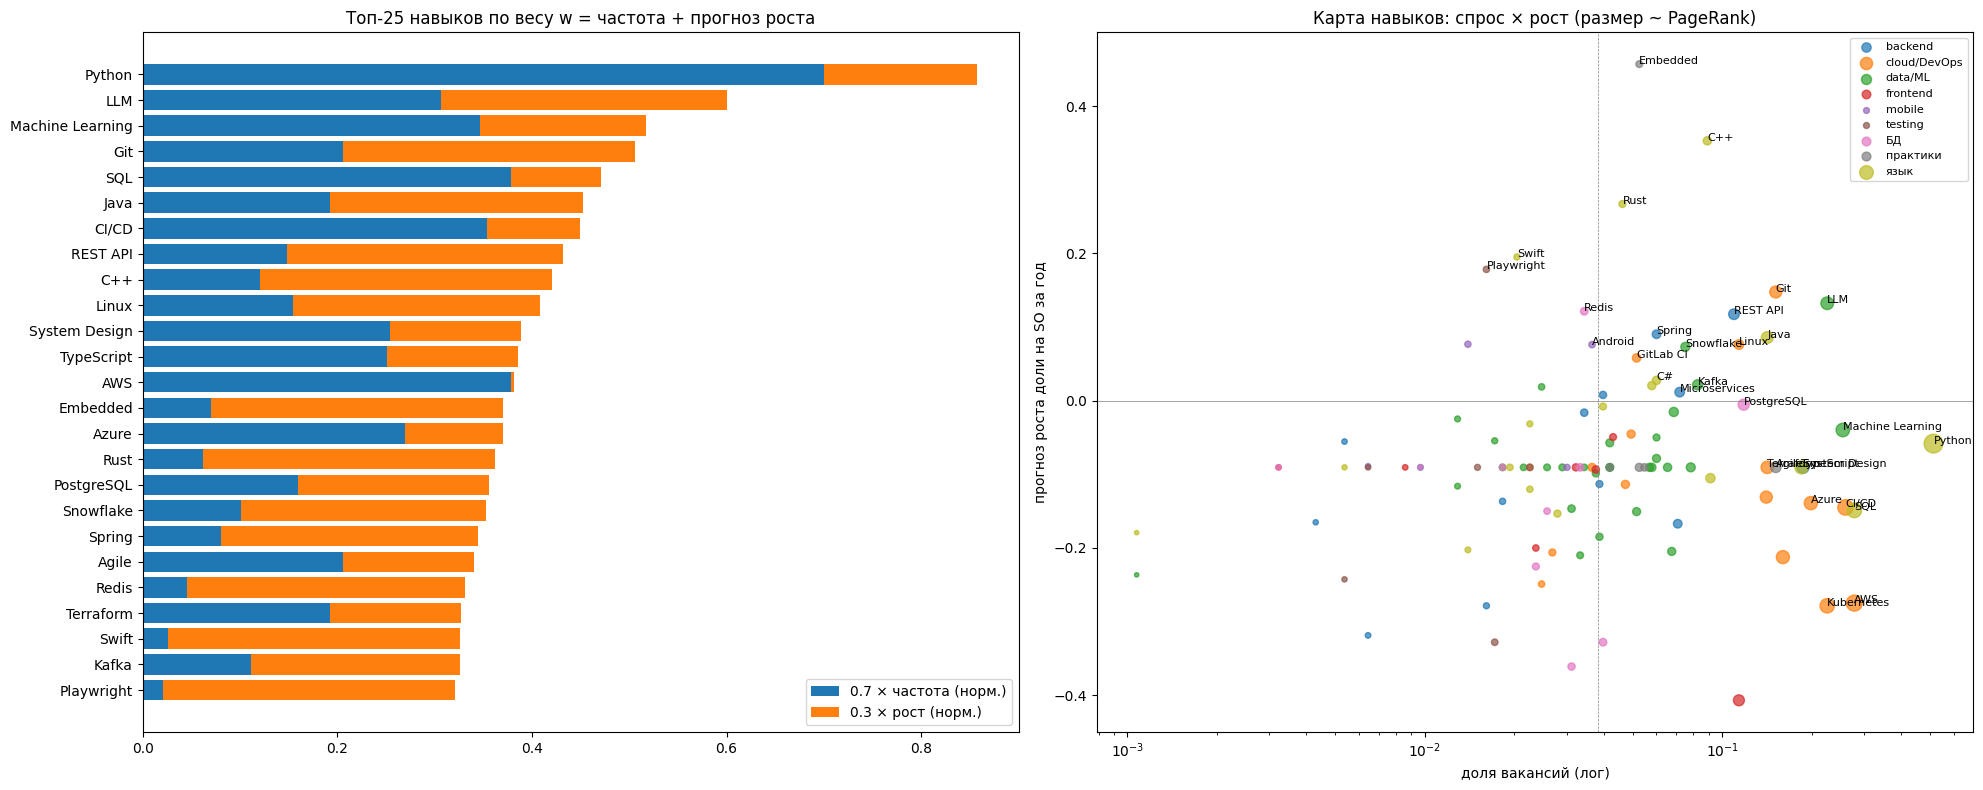

In [13]:
with torch.no_grad():
    Z = model(data.to(device))                     # инференс на полном графе (модель индуктивна)
S_proj = torch.sigmoid(model.all_scores(Z, "project")).cpu().numpy()
gnn_role = pd.DataFrame({r: S_proj[(it["role"] == r).values].mean(0) for r in roles}, index=skill_list).T
skills_df["gnn_importance"] = skills_df["skill"].map(gnn_role.mean(0))
skills_df["pagerank"] = skills_df["skill"].map(skill_pr).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
top25 = skills_df.head(25).iloc[::-1]
axes[0].barh(top25["skill"], 0.7 * top25["freq_n"], label="0.7 × частота (норм.)")
axes[0].barh(top25["skill"], 0.3 * top25["growth_n"], left=0.7 * top25["freq_n"], label="0.3 × рост (норм.)")
axes[0].set_title("Топ-25 навыков по весу w = частота + прогноз роста"); axes[0].legend()

cmap = plt.get_cmap("tab10")
for k, c in enumerate(cats):
    sub = skills_df[skills_df["category"] == c]
    axes[1].scatter(sub["freq"], sub["growth"], s=3000 * sub["pagerank"] + 10, color=cmap(k), alpha=0.7, label=c)
for _, r in skills_df.head(30).iterrows():
    axes[1].annotate(r["skill"], (r["freq"], r["growth"]), fontsize=8)
axes[1].set_xscale("log"); axes[1].axhline(0, color="gray", lw=0.5)
axes[1].axvline(skills_df["freq"].median(), color="gray", lw=0.5, ls="--")
axes[1].set_xlabel("доля вакансий (лог)"); axes[1].set_ylabel("прогноз роста доли на SO за год")
axes[1].set_title("Карта навыков: спрос × рост (размер ~ PageRank)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

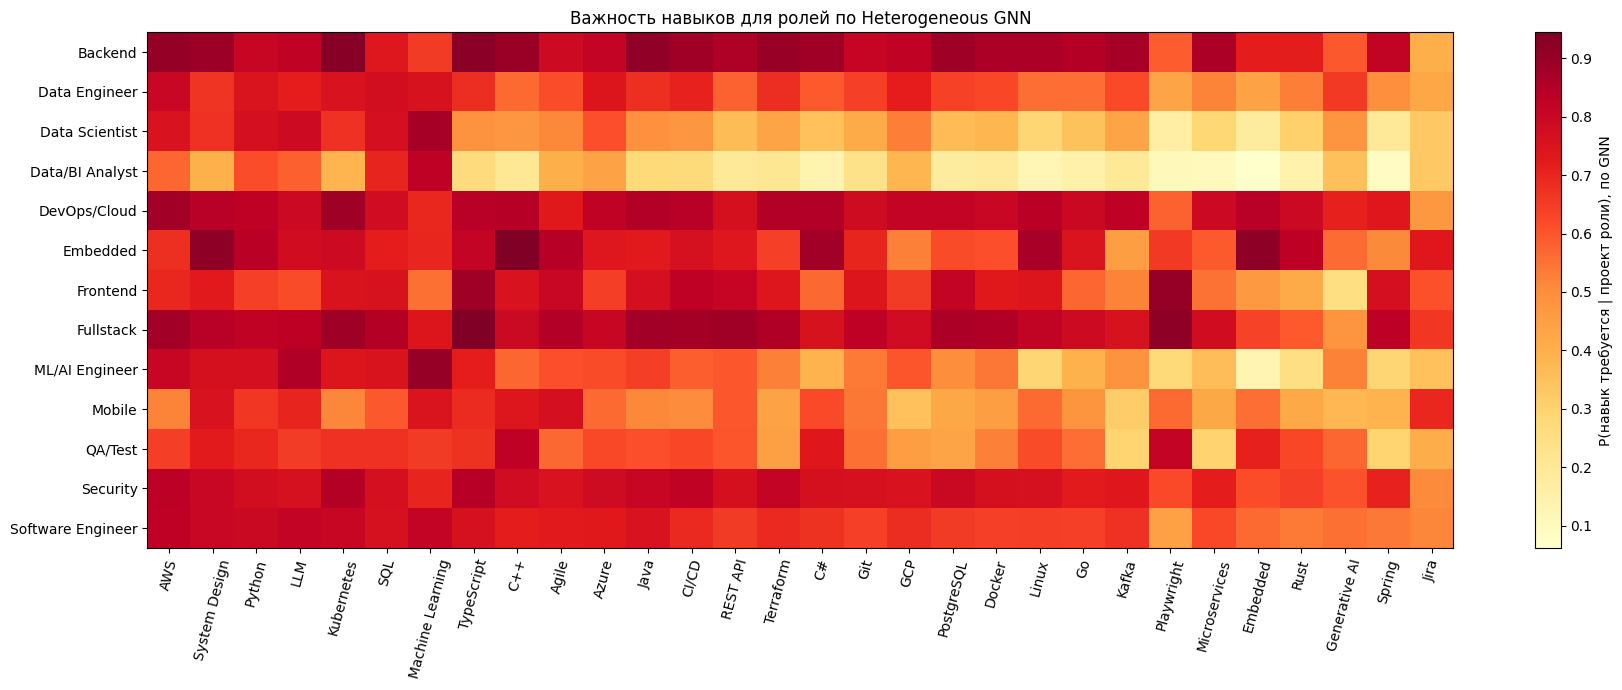

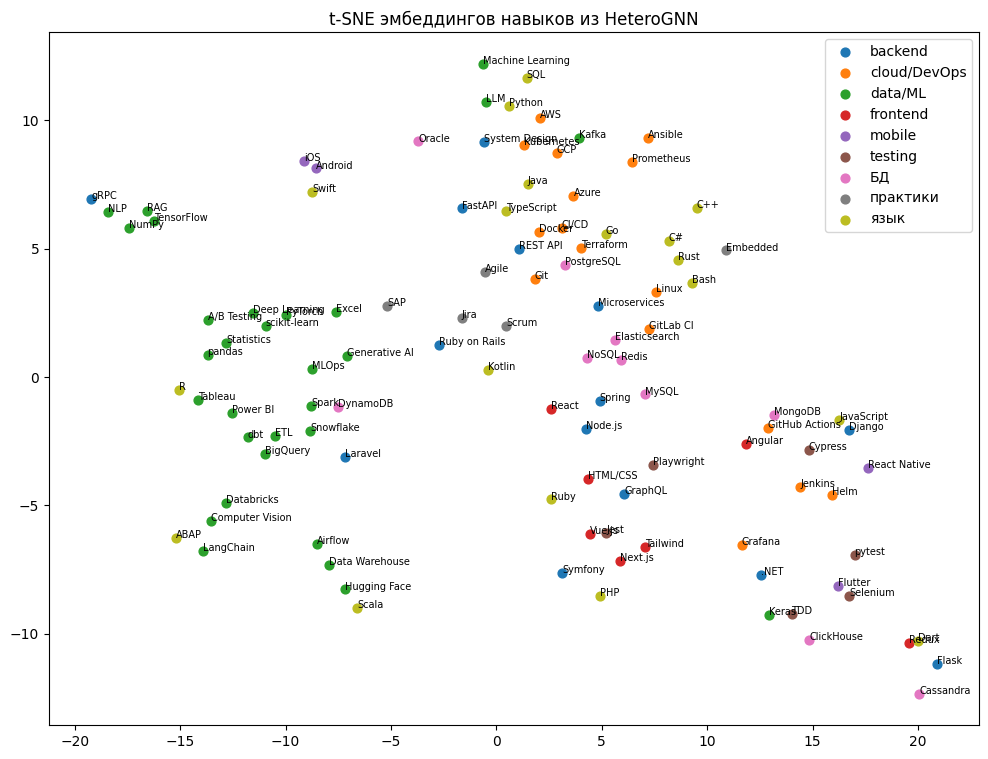

In [14]:
top_sk = skills_df.sort_values("gnn_importance", ascending=False)["skill"].head(30).tolist()
plt.figure(figsize=(18, 7))
plt.imshow(gnn_role[top_sk].values, aspect="auto", cmap="YlOrRd")
plt.xticks(range(len(top_sk)), top_sk, rotation=75); plt.yticks(range(len(roles)), roles)
plt.colorbar(label="P(навык требуется | проект роли), по GNN")
plt.title("Важность навыков для ролей по Heterogeneous GNN")
plt.tight_layout(); plt.show()

emb = TSNE(n_components=2, random_state=SEED, perplexity=15).fit_transform(Z["skill"].cpu().numpy())
plt.figure(figsize=(12, 9))
for k, c in enumerate(cats):
    m = (skills_df["category"] == c).values
    plt.scatter(emb[m, 0], emb[m, 1], color=cmap(k), label=c, s=40)
for k, s in enumerate(skill_list):
    plt.annotate(s, emb[k], fontsize=7)
plt.legend(); plt.title("t-SNE эмбеддингов навыков из HeteroGNN"); plt.show()

In [15]:
# Интерактивный граф компетенций: навыки (размер ~ вес) и роли
from pyvis.network import Network

def show_html_file(path, height=700):
    content = open(path, encoding="utf-8").read()
    display(HTML('<iframe srcdoc="{}" width="100%" height="{}" style="border:1px solid #ddd"></iframe>'.format(html.escape(content), height)))

net = Network(height="650px", width="100%", notebook=True, cdn_resources="remote")
palette = {c: f"#{int(255 * cmap(k)[0]):02x}{int(255 * cmap(k)[1]):02x}{int(255 * cmap(k)[2]):02x}" for k, c in enumerate(cats)}
for _, r in skills_df.iterrows():
    net.add_node(r["skill"], label=r["skill"], color=palette[r["category"]], size=8 + 40 * r["weight"],
                 title=f"{r['skill']} ({r['category']})\nвакансий: {r['count']} ({r['freq']:.1%})\nрост: {r['growth']:+.1%}\nвес: {r['weight']:.3f}")
for r in roles:
    net.add_node("ROLE: " + r, label=r, shape="box", color="#ff6b6b")
    for s in role_share.loc[r].sort_values(ascending=False).head(6).index:
        net.add_edge("ROLE: " + r, s, value=float(role_share.loc[r, s]), title=f"требуется в {role_share.loc[r, s]:.0%} вакансий", color="#ffaaaa")
for a, b, d in SG.edges(data=True):
    if d["count"] >= 15 and d["pmi"] > 0.3:
        net.add_edge(a, b, value=d["count"], title=f"вместе в {d['count']} вакансиях, PMI {d['pmi']:.2f}", color="#cccccc")
net.force_atlas_2based(gravity=-60, spring_length=120)
net.save_graph("competency_graph.html")
show_html_file("competency_graph.html")

## 4. Персонализированные рекомендации и путь обучения

**Кандидаты** — навыки, которыми человек ещё не владеет и которые связаны с целевой ролью ребром `required_for`
(встречаются хотя бы в 5% вакансий роли). **Скоринг** навыка-кандидата $s$ для человека $p$ с целевой ролью $r$:
$$\text{score}(p,s) = 0.35 \cdot \widetilde{\text{GNN}}(p,s) + 0.45 \cdot \widetilde{\text{role}}(r,s) + 0.20 \cdot w_s$$
- $\text{GNN}(p,s) = \sigma(z_p^\top z_s + b_s)$ — насколько навык «естественен» для профиля человека (учитывает и текущие навыки, и целевую роль через граф);
- $\text{role}(r,s)$ — доля вакансий целевой роли, где требуется навык;
- $w_s$ — рыночный вес (частота + прогноз роста).

**Порядок изучения.** Навык $a$ считается предпосылкой для $b$, если в вакансиях с $b$ навык $a$ встречается часто ($P(a\mid b)\ge 0.4$),
а обратное заметно реже ($P(a\mid b) - P(b\mid a) \ge 0.15$): $a$ более базовый. Получается ориентированный ациклический граф,
и этап навыка равен длине самой длинной цепочки ещё не изученных предпосылок.

**Проекты для практики** («развивает») — вакансии целевой роли, которые максимально опираются на уже имеющиеся навыки и
покрывают как можно больше рекомендованных новых.

Студент финтеха -> Data Scientist | целевая роль: Data Scientist
Уже есть: Excel, Git, NumPy, Python, SQL, Statistics, pandas


,этап,навык,категория,score,GNN,доля в вакансиях «Data Scientist»,прогноз роста,опирается на
0,1,Machine Learning,data/ML,0.901,0.873,0.784,-0.040,Python
1,1,LLM,data/ML,0.566,0.828,0.243,0.132,Python
2,1,AWS,cloud/DevOps,0.501,0.775,0.243,-0.275,Python
3,1,CI/CD,cloud/DevOps,0.439,0.751,0.135,-0.145,Python
4,1,System Design,backend,0.428,0.879,0.054,-0.091,Python
5,1,A/B Testing,data/ML,0.405,0.593,0.270,-0.091,"SQL, Statistics, Python"
6,2,Azure,cloud/DevOps,0.466,0.734,0.216,-0.139,"Python, AWS"
7,3,GCP,cloud/DevOps,0.426,0.670,0.216,-0.131,"Python, Machine Learning, AWS, Azure, CI/CD"


,title,есть,развивает
175,Senior Data Scientist (m/w/d),5,"[A/B Testing, AWS, Azure, CI/CD, GCP, LLM, Mac..."
365,Associate Data Scientist,4,"[A/B Testing, AWS, Azure, GCP, LLM, Machine Le..."
919,Principal Data Scientist - AI,2,"[A/B Testing, AWS, Azure, CI/CD, GCP, LLM, Mac..."


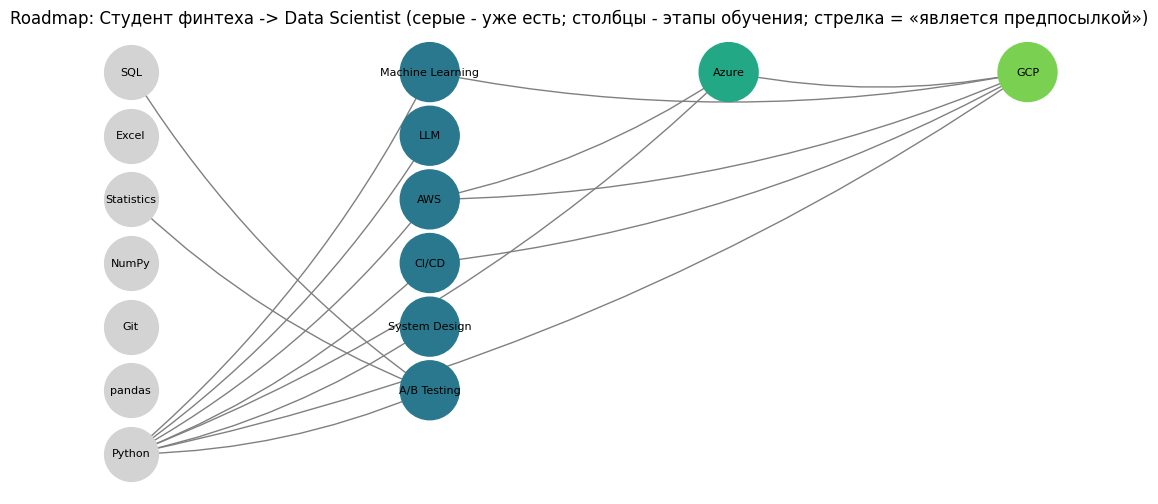

Java backend -> DevOps/Cloud | целевая роль: DevOps/Cloud
Уже есть: Docker, Git, Java, Linux, PostgreSQL, REST API, SQL, Spring


,этап,навык,категория,score,GNN,доля в вакансиях «DevOps/Cloud»,прогноз роста,опирается на
0,1,Python,язык,0.834,0.814,0.528,-0.059,
1,2,Kubernetes,cloud/DevOps,0.849,0.816,0.708,-0.279,Python
2,2,CI/CD,cloud/DevOps,0.756,0.786,0.556,-0.145,Python
3,2,AWS,cloud/DevOps,0.713,0.838,0.472,-0.275,Python
4,2,TypeScript,язык,0.496,0.807,0.181,-0.091,Python
5,2,System Design,backend,0.493,0.835,0.153,-0.091,Python
6,3,Terraform,cloud/DevOps,0.802,0.756,0.681,-0.091,"Kubernetes, Python, CI/CD, AWS"
7,3,Azure,cloud/DevOps,0.573,0.742,0.347,-0.139,"Python, AWS"


,title,есть,развивает
601,Développeur Java / DevOps F/H,5,"[AWS, Azure, CI/CD, Kubernetes, Terraform]"
216,Staff Site Reliability Engineer (x/f/m),1,"[AWS, Azure, Kubernetes, Python, System Design..."
217,Senior Site Reliability Engineer (x/f/m),1,"[AWS, Azure, Kubernetes, Python, System Design..."


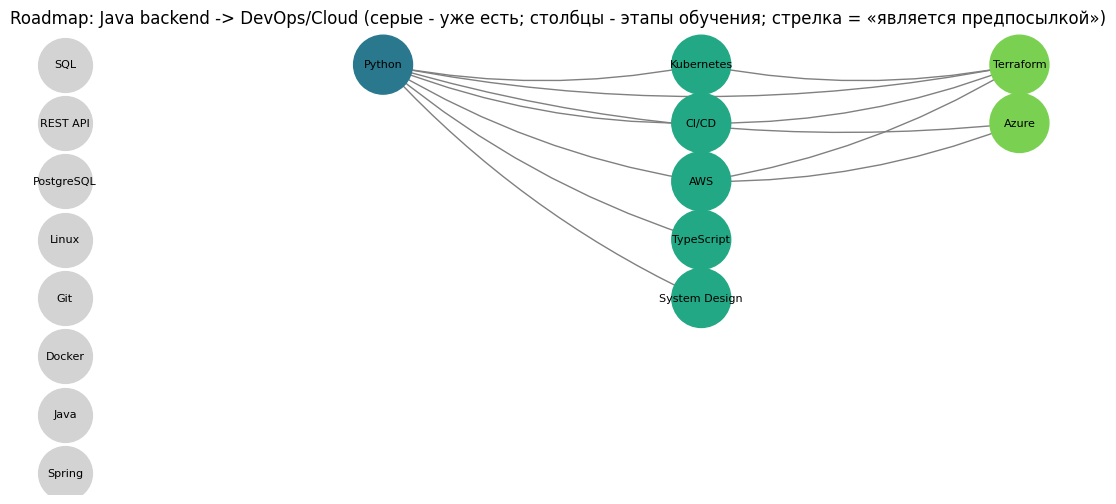

Frontend -> ML/AI Engineer | целевая роль: ML/AI Engineer
Уже есть: Git, HTML/CSS, JavaScript, Python, React, TypeScript


,этап,навык,категория,score,GNN,доля в вакансиях «ML/AI Engineer»,прогноз роста,опирается на
0,1,LLM,data/ML,0.904,0.806,0.607,0.132,Python
1,1,Machine Learning,data/ML,0.851,0.787,0.583,-0.040,Python
2,1,AWS,cloud/DevOps,0.605,0.825,0.276,-0.275,Python
3,1,System Design,backend,0.602,0.825,0.270,-0.091,Python
4,1,CI/CD,cloud/DevOps,0.543,0.795,0.215,-0.145,Python
5,1,SQL,язык,0.537,0.800,0.196,-0.149,Python
6,1,Kubernetes,cloud/DevOps,0.529,0.823,0.202,-0.279,Python
7,2,RAG,data/ML,0.546,0.822,0.245,-0.091,"Python, LLM, Machine Learning, Kubernetes"


,title,есть,развивает
591,AI Engineer H/F - Paris,2,"[AWS, CI/CD, Kubernetes, LLM, Machine Learning..."
523,Agentic AI Software Engineer,1,"[AWS, CI/CD, Kubernetes, LLM, Machine Learning..."
738,"Senior AI Engineer, Agents & Applications",1,"[CI/CD, Kubernetes, LLM, Machine Learning, RAG..."


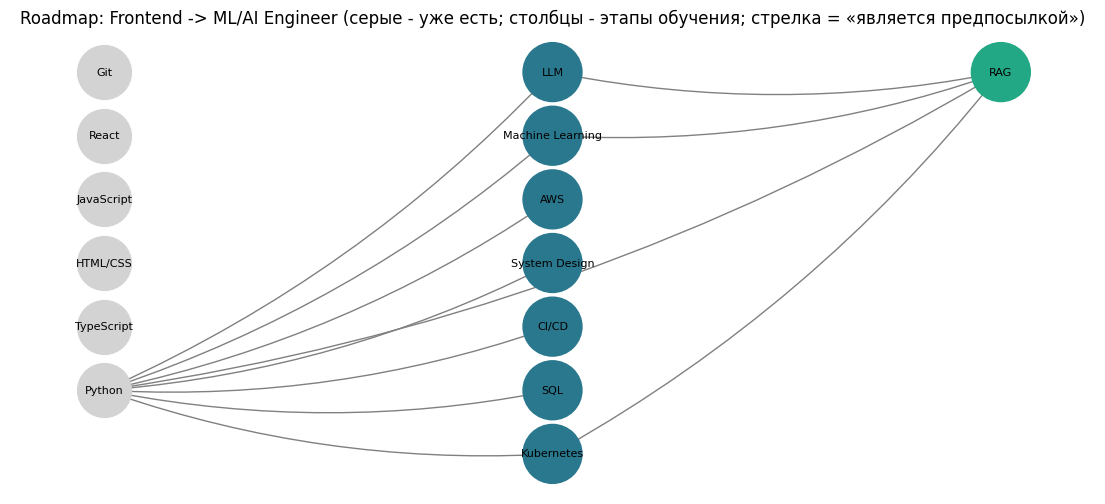

In [16]:
S_person = torch.sigmoid(model.all_scores(Z, "person")).cpu().numpy()
skill_cnt = dict(zip(skills_df["skill"], skills_df["count"]))

def cond(a, b):
    """P(a | b) по вакансиям."""
    key = tuple(sorted((a, b)))
    return pair_cnt.get(key, 0) / skill_cnt[b]

def roadmap(name, top_n=8):
    pi = people.index[people["name"] == name][0]
    have, target = set(people.loc[pi, "skills"]), people.loc[pi, "target"]
    cand = [s for s in skill_list if s not in have and role_share.loc[target, s] >= 0.05]
    g = pd.Series(S_person[pi, [sidx[s] for s in cand]], index=cand)
    rs = role_share.loc[target, cand]
    score = 0.35 * mm(g) + 0.45 * mm(rs) + 0.20 * pd.Series(w_skill)[cand]
    rec = score.sort_values(ascending=False).head(top_n).index.tolist()

    # граф предпосылок на имеющихся + рекомендованных навыках
    D = nx.DiGraph(); D.add_nodes_from(list(have) + rec)
    for a in D:
        for b in rec:
            if a != b and cond(a, b) >= 0.4 and cond(a, b) - cond(b, a) >= 0.15:
                D.add_edge(a, b)
    stage = {s: 0 for s in have}
    for s in nx.topological_sort(D):
        if s in rec:
            stage[s] = 1 + max([stage[p] for p in D.predecessors(s) if p in rec] + [0])
    table = pd.DataFrame({
        "этап": [stage[s] for s in rec], "навык": rec, "категория": [CATEGORY[s] for s in rec],
        "score": score[rec].values, "GNN": g[rec].values, f"доля в вакансиях «{target}»": rs[rec].values,
        "прогноз роста": [skills_df.set_index("skill").loc[s, "growth"] for s in rec],
        "опирается на": [", ".join(p for p in D.predecessors(s)) for s in rec],
    }).sort_values(["этап", "score"], ascending=[True, False]).reset_index(drop=True)

    # проекты для практики
    pr = it[it["role"] == target].copy()
    pr["есть"] = pr["skills"].map(lambda ss: len(set(ss) & have))
    pr["развивает"] = pr["skills"].map(lambda ss: sorted(set(ss) & set(rec)))
    pr["k"] = pr["есть"] + 1.5 * pr["развивает"].map(len)
    projects = pr.sort_values("k", ascending=False).head(3)[["title", "есть", "развивает"]]
    return have, target, table, D, stage, projects

def draw_roadmap(name, have, D, stage, rec):
    pos, cnt = {}, Counter()
    for s in D:
        st = stage[s]; pos[s] = (st, -cnt[st]); cnt[st] += 1
    plt.figure(figsize=(14, 6))
    nx.draw_networkx_edges(D, pos, edge_color="gray", arrows=True, arrowsize=15, connectionstyle="arc3,rad=0.1")
    nx.draw_networkx_nodes(D, pos, nodelist=list(have), node_color="lightgray", node_size=1500)
    nx.draw_networkx_nodes(D, pos, nodelist=rec, node_color=[plt.cm.viridis(0.2 + 0.2 * stage[s]) for s in rec], node_size=1800)
    nx.draw_networkx_labels(D, pos, font_size=8)
    plt.title(f"Roadmap: {name} (серые - уже есть; столбцы - этапы обучения; стрелка = «является предпосылкой»)")
    plt.xticks(range(max(stage.values()) + 1), ["уже есть"] + [f"этап {k}" for k in range(1, max(stage.values()) + 1)])
    plt.gca().get_yaxis().set_visible(False); plt.box(False); plt.show()

roadmaps = {}
for name in PERSONAS:
    have, target, table, D, stage, projects = roadmap(name)
    roadmaps[name] = (target, table, projects)
    print("=" * 100); print(name, "| целевая роль:", target); print("Уже есть:", ", ".join(sorted(have)))
    display(table.round(3)); display(projects)
    draw_roadmap(name, have, D, stage, table["навык"].tolist())

In [17]:
# Текстовые рекомендации
for name, (target, table, projects) in roadmaps.items():
    print(f"\n### {name}")
    for st, grp in table.groupby("этап"):
        items = [f"{r['навык']} (в {r.iloc[5]:.0%} вакансий роли, рост {r['прогноз роста']:+.0%})" for _, r in grp.iterrows()]
        print(f"  Этап {st}: " + "; ".join(items))
    p = projects.iloc[0]
    print(f"  Проект для практики: «{p['title']}» - опирается на {p['есть']} ваших навыков, развивает: {', '.join(p['развивает'])}")


### Студент финтеха -> Data Scientist
  Этап 1: Machine Learning (в 78% вакансий роли, рост -4%); LLM (в 24% вакансий роли, рост +13%); AWS (в 24% вакансий роли, рост -28%); CI/CD (в 14% вакансий роли, рост -15%); System Design (в 5% вакансий роли, рост -9%); A/B Testing (в 27% вакансий роли, рост -9%)
  Этап 2: Azure (в 22% вакансий роли, рост -14%)
  Этап 3: GCP (в 22% вакансий роли, рост -13%)
  Проект для практики: «Senior Data Scientist (m/w/d)» - опирается на 5 ваших навыков, развивает: A/B Testing, AWS, Azure, CI/CD, GCP, LLM, Machine Learning

### Java backend -> DevOps/Cloud
  Этап 1: Python (в 53% вакансий роли, рост -6%)
  Этап 2: Kubernetes (в 71% вакансий роли, рост -28%); CI/CD (в 56% вакансий роли, рост -15%); AWS (в 47% вакансий роли, рост -28%); TypeScript (в 18% вакансий роли, рост -9%); System Design (в 15% вакансий роли, рост -9%)
  Этап 3: Terraform (в 68% вакансий роли, рост -9%); Azure (в 35% вакансий роли, рост -14%)
  Проект для практики: «Développeur Java / D

## Выводы

1. **Данные.** Собраны реальные вакансии (Arbeitnow; код для hh.ru подготовлен и включается флагом). Из текстов по словарю
   извлечены ~100 технологий, вакансии распределены по 13 ролям. Прогноз роста оценён по трёхлетнему тренду доли вопросов
   на Stack Overflow. Это внешний и независимый от вакансий индикатор популярности технологии.
2. **Граф компетенций.** Самые востребованные навыки (по частоте и PageRank в графе совместной встречаемости) — базовые
   «связующие» технологии: Python, SQL, облака (AWS/Azure), Docker/Kubernetes, CI/CD; заметную долю уже занимают LLM.
   По тренду Stack Overflow относительно растут системные языки (C++, Rust, Swift), embedded-разработка, LLM и Playwright,
   а падают зрелые веб-стеки и облачные инструменты (React, Django/Flask, MySQL, AWS, Kubernetes). Это относительный показатель:
   общее число вопросов на SO упало в разы, и вопросы по массовым технологиям быстрее всего уходят к ИИ-ассистентам.
   Карта «спрос × рост» отделяет «обязательную базу» (высокий спрос) от «ставок на будущее» (высокий рост при пока небольшом спросе).
3. **Heterogeneous GNN** (GraphSAGE + `to_hetero`) на графе «человек – навык – проект – роль»:
   - на **реальных** связях `project–requires–skill` модель превосходит бейзлайн популярности по ROC-AUC, AP и Recall@10,
     то есть учитывает контекст проекта: роль и сочетаемость навыков;
   - на **смоделированных** связях `person–has–skill` модель примерно на уровне популярности. Это ожидаемо: профили людей
     генерировались с примесью случайных популярных навыков, и эта часть принципиально непредсказуема. Поэтому в roadmap
     сигнал GNN комбинируется с требованиями целевой роли.

   Тепловая карта «роль × навык» по GNN и t-SNE эмбеддингов показывают осмысленные группы: data/ML, облака и DevOps,
   фронтенд, мобильная разработка.
4. **Персонализированный roadmap** сочетает три сигнала: GNN (что естественно для профиля), требования целевой роли и рыночный вес.
   Порядок изучения выводится из асимметрии условных вероятностей совместной встречаемости. Для каждой персоны получен
   поэтапный план и проекты для практики, которые опираются на имеющиеся навыки и развивают новые.
5. **Ограничения.** Источник вакансий — европейский рынок, а не hh.ru. Словарь навыков ручной: soft skills и редкие технологии не учтены.
   Популяция людей смоделирована по вакансиям, реальные резюме улучшили бы рекомендации. Рост по Stack Overflow отражает
   интерес разработчиков, а не напрямую спрос работодателей.

## Источники
1. API hh.ru: https://api.hh.ru/openapi/redoc ; Arbeitnow Job Board API: https://www.arbeitnow.com/api/job-board-api
2. StackExchange API: https://api.stackexchange.com/docs
3. PyTorch Geometric, гетерогенные графы: https://pytorch-geometric.readthedocs.io/en/latest/notes/heterogeneous.html
4. Hamilton W., Ying R., Leskovec J. *Inductive Representation Learning on Large Graphs* (GraphSAGE), NeurIPS 2017.
5. Schlichtkrull M. et al. *Modeling Relational Data with Graph Convolutional Networks* (R-GCN), ESWC 2018.
6. Wang X. et al. *Heterogeneous Graph Attention Network*, WWW 2019.
7. Page L., Brin S. et al. *The PageRank Citation Ranking*, 1999.